In [1]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

from astropy.table import vstack

In [2]:
ROMAN = ascii.read("../sims/ROMAN/FITOPT000_ROMAN.FITRES")
ROMAN_max = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MAX.FITRES")
ROMAN_med = ascii.read("../sims/ROMAN/FITOPT000_ROMAN_EBV_IGM_MED.FITRES")

In [3]:
DES = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21.FITRES")
DES_max = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX.FITRES")

In [4]:
LSST_highz = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ.FITRES")

In [5]:
LSST_highz_max = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MAX.FITRES")

In [6]:
LSST_highz_med = ascii.read("../sims/LSST/HIGHZ/DDF_FITOPT000_BBC_LSST_HIGHZ_EBV_IGM_MED.FITRES")

In [7]:
LSST_lowz = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ.FITRES")
LSST_lowz_max = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MAX.FITRES")
LSST_lowz_med = ascii.read("../sims/LSST/LOWZ/FITOPT000_BBC_LSST_LOWZ_EBV_IGM_MED.FITRES")

In [8]:
LSST = vstack([LSST_lowz,LSST_highz])
LSST_max = vstack([LSST_lowz_max,LSST_highz_max])
LSST_med = vstack([LSST_lowz_med,LSST_highz_med])

In [9]:
def create_filt(file):
    
    filt = (np.abs(file['c']) < 0.3) & (np.abs(file['x1']) < 3) & (file['x1ERR'] < 1) & (file['PKMJDERR'] < 2) & (file['FITPROB'] > 0.001) & (file['SIM_AV'] > -9)
    
    return filt

In [10]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

In [11]:
def plot_mu_dif(nodust,dust,label="",color="",alpha=1):
    mures = nodust['mB']+0.14*nodust['x1']-3.1*nodust['c']+19.35-nodust['SIM_DLMAG']
    corr_mures = dust['mB']+0.14*dust['x1']-3.1*dust['c']+19.35-dust['SIM_DLMAG']

    bin_edges1, mu_bin_means1, mu_bin_std1 = bin_vals(nodust['zHD'],mures)
    bin_edges2, mu_bin_means2, mu_bin_std2 = bin_vals(dust['zHD'],corr_mures)

#     plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2, mu_bin_means1,yerr=mu_bin_std1,
#                  ls = 'none',marker='s', c='C3', label='nodust')
#     plt.errorbar((bin_edges2[:-1] + bin_edges2[1:]) / 2, mu_bin_means2,yerr=mu_bin_std2,
#                  ls = 'none',marker='s', c='C4', label='dust')

#     plt.ylabel("$\mu_\mathrm{res}$ (mag)",fontsize=14)
#     plt.xlabel("$z$",fontsize=14)
#     plt.legend()

#     plt.show()
    
#     plt.figure(figsize=(6,4.5))
    plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,label=label,zorder=20,color=color,alpha=alpha)
    plt.errorbar((bin_edges1[:-1] + bin_edges1[1:]) / 2,mu_bin_means2-mu_bin_means1,
                 yerr=np.sqrt(mu_bin_std1**2+mu_bin_std2**2),
                 ls = 'none',alpha=0.8*alpha,fmt='none',c='k',elinewidth=0.5,zorder=2)
    # plt.scatter((bin_edges1[:-1] + bin_edges1[1:]) / 2,1*(bin_means3-bin_means1),label="BS20_corr - BS20")
    plt.xlabel("$z$",fontsize=14)
    plt.ylabel("$\Delta\mu$ (mag)",fontsize=14)
    plt.legend(fontsize=14,loc='upper left')
    plt.axhline(c='k',ls='--',zorder=1)
#     plt.ylim(-0.005,0.03)
    # plt.savefig("pdfs/mu_from_igdust.pdf",bbox_inches='tight')
    # plt.savefig("pngs/mu_from_igdust.png",bbox_inches='tight')
#     plt.show()

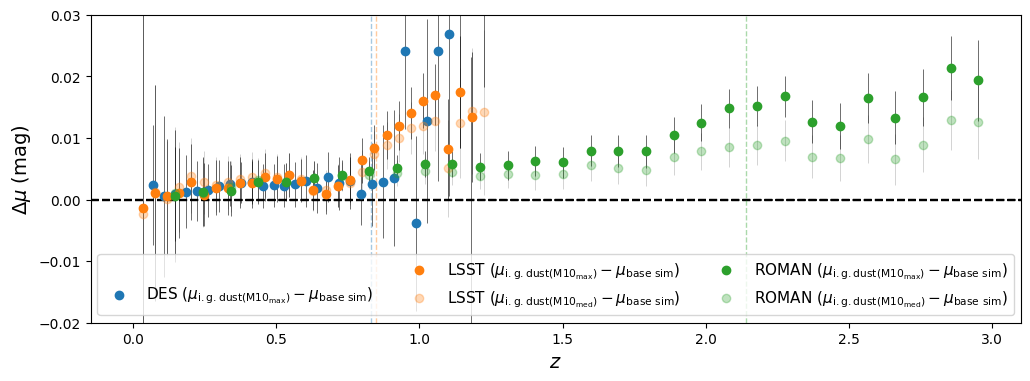

In [12]:
plt.figure(figsize=(12,4))
plt.scatter(0,0,c="white",label=" ")
plot_mu_dif(DES[create_filt(DES)&(np.isin(DES['FIELD'],['X3','C3']))],DES_max[create_filt(DES_max)&(np.isin(DES_max['FIELD'],['X3','C3']))],label="DES ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)",color="C0")
plot_mu_dif(LSST[create_filt(LSST)&(np.isin(LSST['FIELD'],['DDF']))],LSST_max[create_filt(LSST_max)&(np.isin(LSST_max['FIELD'],['DDF']))],label="LSST ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)",color="C1")
plot_mu_dif(LSST[create_filt(LSST)&(np.isin(LSST['FIELD'],['DDF']))],LSST_med[create_filt(LSST_med)&(np.isin(LSST_med['FIELD'],['DDF']))],label="LSST ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{base\ sim}$)",color="C1",alpha=0.3)
plot_mu_dif(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_max[create_filt(ROMAN_max)&(np.isin(ROMAN_max['FIELD'],['DEEP']))],label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)",color="C2")
plot_mu_dif(ROMAN[create_filt(ROMAN)&(np.isin(ROMAN['FIELD'],['DEEP']))],ROMAN_med[create_filt(ROMAN_med)&(np.isin(ROMAN_med['FIELD'],['DEEP']))],label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{base\ sim}$)",color="C2",alpha=0.3)
plt.ylim(-0.02,0.03)


plt.axvline(x=0.83,ls='--',c='C0',alpha=0.4,lw=1)
plt.axvline(x=0.85,ls='--',c='C1',alpha=0.4,lw=1)
plt.axvline(x=2.14,ls='--',c='C2',alpha=0.4,lw=1)

plt.legend(loc="lower center",ncol=3,fontsize=11)
# plt.savefig("pdfs/combined_mu_dif.pdf",bbox_inches='tight')
plt.show()

In [16]:
# def plot_mu_dif(nodust, dust, label="", color="", alpha=1):
#     mures      = nodust['mB'] + 0.14*nodust['x1'] - 3.1*nodust['c'] + 19.35 - nodust['SIM_DLMAG']
#     corr_mures = dust['mB']   + 0.14*dust['x1']   - 3.1*dust['c']   + 19.35 - dust['SIM_DLMAG']

#     bin_edges1, mu_bin_means1, mu_bin_std1 = bin_vals(nodust['zHD'], mures)
#     bin_edges2, mu_bin_means2, mu_bin_std2 = bin_vals(dust['zHD'], corr_mures)

#     zc   = (bin_edges1[:-1] + bin_edges1[1:]) / 2
#     dmu  = np.asarray(mu_bin_means2 - mu_bin_means1)
#     err  = np.asarray(np.sqrt(mu_bin_std1**2 + mu_bin_std2**2))

#     plt.scatter(zc, dmu, label=label, zorder=20, color=color, alpha=alpha)
#     plt.errorbar(zc, dmu, yerr=err, ls='none', alpha=0.8*alpha, fmt='none',
#                  c='k', elinewidth=0.5, zorder=2)
#     plt.xlabel("$z$", fontsize=14)
#     plt.ylabel("$\Delta\mu$ (mag)", fontsize=14)
#     plt.axhline(c='k', ls='--', zorder=1)
#     return zc, dmu, err

# # ---- Plot ----
# plt.figure(figsize=(12,4))
# plt.scatter(0, 0, c="white", label=" ")

# des_nd   = DES[create_filt(DES) & np.isin(DES['FIELD'], ['X3','C3'])]
# lsst_nd  = LSST[create_filt(LSST) & np.isin(LSST['FIELD'], ['DDF'])]
# roman_nd = ROMAN[create_filt(ROMAN) & np.isin(ROMAN['FIELD'], ['DEEP'])]

# res = {}
# res["DES max"]   = plot_mu_dif(des_nd,   DES_max[create_filt(DES_max) & np.isin(DES_max['FIELD'], ['X3','C3'])],
#                                label="DES ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)", color="C0")
# res["LSST max"]  = plot_mu_dif(lsst_nd,  LSST_max[create_filt(LSST_max) & np.isin(LSST_max['FIELD'], ['DDF'])],
#                                label="LSST ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)", color="C1")
# res["LSST med"]  = plot_mu_dif(lsst_nd,  LSST_med[create_filt(LSST_med) & np.isin(LSST_med['FIELD'], ['DDF'])],
#                                label="LSST ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{base\ sim}$)", color="C1", alpha=0.3)
# res["ROMAN max"] = plot_mu_dif(roman_nd, ROMAN_max[create_filt(ROMAN_max) & np.isin(ROMAN_max['FIELD'], ['DEEP'])],
#                                label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{max})} - \mu_\mathrm{base\ sim}$)", color="C2")
# res["ROMAN med"] = plot_mu_dif(roman_nd, ROMAN_med[create_filt(ROMAN_med) & np.isin(ROMAN_med['FIELD'], ['DEEP'])],
#                                label="ROMAN ($\mu_\mathrm{i.g.dust(M10_{med})} - \mu_\mathrm{base\ sim}$)", color="C2", alpha=0.3)

# plt.ylim(-0.02, 0.03)
# plt.axvline(x=0.83, ls='--', c='C0', alpha=0.4, lw=1)
# plt.axvline(x=0.85, ls='--', c='C1', alpha=0.4, lw=1)
# plt.axvline(x=2.14, ls='--', c='C2', alpha=0.4, lw=1)
# plt.legend(loc="lower center", ncol=3, fontsize=11)
# # plt.savefig("pdfs/combined_mu_dif.pdf", bbox_inches='tight')
# plt.show()

# # ---- Significance per bin ----
# df = pd.concat([pd.DataFrame(dict(sample=k, z=z, dmu=d, sigma=e))
#                 for k, (z, d, e) in res.items()], ignore_index=True)
# df = df[(df.sigma > 0) & np.isfinite(df.dmu)].copy()
# df["nsig"] = df.dmu / df.sigma
# df["abs_nsig"] = df.nsig.abs()

# pd.set_option("display.float_format", "{:.4f}".format)
# print("Top 30 bins overall (|Δμ/σ|):")
# print(df.sort_values("abs_nsig", ascending=False).head(30).drop(columns="abs_nsig").to_string(index=False))

# print("\nMost significant bin per sample:")
# print(df.loc[df.groupby("sample").abs_nsig.idxmax()].drop(columns="abs_nsig").to_string(index=False))

# print("\nWhole-sample chi² vs zero (assumes independent bins):")
# print(df.groupby("sample").agg(chi2=("nsig", lambda x: (x**2).sum()), nbins=("nsig", "size")).to_string())